In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from qick import *
from tqdm.notebook import tqdm
from tqdm.contrib import tenumerate
import time
import pandas as pd
from pathlib import Path
from scipy.optimize import curve_fit
import json

mpl.rcParams['figure.figsize'] = 12, 8
mpl.rcParams.update({'font.size': 12})


In [2]:
soc = QickSoc()
soccfg = soc
print(soc)

QICK running on RFSoC4x2, software version 0.2.405

Firmware configuration (built Wed Sep  6 18:49:29 2023):

	Global clocks (MHz): tProc dispatcher timing 409.600, RF reference 491.520
	Groups of related clocks: [tProc clock, DAC tile 0], [DAC tile 2], [ADC tile 0]

	2 signal generator channels:
	0:	axis_signal_gen_v6 - fs=9830.400 Msps, fabric=614.400 MHz
		envelope memory: 65536 complex samples (6.667 us)
		32-bit DDS, range=9830.400 MHz
		DAC tile 0, blk 0 is DAC_B
	1:	axis_signal_gen_v6 - fs=9830.400 Msps, fabric=614.400 MHz
		envelope memory: 65536 complex samples (6.667 us)
		32-bit DDS, range=9830.400 MHz
		DAC tile 2, blk 0 is DAC_A

	2 readout channels:
	0:	axis_readout_v2 - configured by PYNQ
		fs=4423.680 Msps, decimated=552.960 MHz, 32-bit DDS, range=4423.680 MHz
		axis_avg_buffer v1.0 (no edge counter, no weights)
		memory 16384 accumulated, 1024 decimated (1.852 us)
		triggered by output 7, pin 14, feedback to tProc input 0
		ADC tile 0, blk 0 is ADC_D
	1:	axis_readout_v

In [3]:
#helper functions

def hist(data=None, plot=True, ran=1.0):
    
    ig = np.array(data[0])
    qg = np.array(data[1])
    ie = np.array(data[2])
    qe = np.array(data[3])

    numbins = 100
    
    xg, yg = np.median(ig), np.median(qg)
    xe, ye = np.median(ie), np.median(qe)

    if plot==True:
        fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
        fig.tight_layout()

        axs[0].scatter(ig, qg, label='g', color='b', marker='*')
        axs[0].scatter(ie, qe, label='e', color='r', marker='*')
        axs[0].scatter(xg, yg, color='k', marker='o')
        axs[0].scatter(xe, ye, color='k', marker='o')
        axs[0].set_xlabel('I (a.u.)')
        axs[0].set_ylabel('Q (a.u.)')
        axs[0].legend(loc='upper right')
        axs[0].set_title('Unrotated')
        axs[0].axis('equal')
    """Compute the rotation angle"""
    theta = -np.arctan2((ye-yg),(xe-xg))
    """Rotate the IQ data"""
    ig_new = ig*np.cos(theta) - qg*np.sin(theta)
    qg_new = ig*np.sin(theta) + qg*np.cos(theta) 
    ie_new = ie*np.cos(theta) - qe*np.sin(theta)
    qe_new = ie*np.sin(theta) + qe*np.cos(theta)
    
    """New means of each blob"""
    xg, yg = np.median(ig_new), np.median(qg_new)
    xe, ye = np.median(ie_new), np.median(qe_new)
    
    #print(xg, xe)
    
    xlims = [xg-ran, xg+ran]
    ylims = [yg-ran, yg+ran]

    if plot==True:
        axs[1].scatter(ig_new, qg_new, label='g', color='b', marker='*')
        axs[1].scatter(ie_new, qe_new, label='e', color='r', marker='*')
        axs[1].scatter(xg, yg, color='k', marker='o')
        axs[1].scatter(xe, ye, color='k', marker='o')    
        axs[1].set_xlabel('I (a.u.)')
        axs[1].legend(loc='lower right')
        axs[1].set_title('Rotated')
        axs[1].axis('equal')

        """X and Y ranges for histogram"""
        
        ng, binsg, pg = axs[2].hist(ig_new, bins=numbins, range = xlims, color='b', label='g', alpha=0.5)
        ne, binse, pe = axs[2].hist(ie_new, bins=numbins, range = xlims, color='r', label='e', alpha=0.5)
        axs[2].set_xlabel('I(a.u.)')       
        
    else:        
        ng, binsg = np.histogram(ig_new, bins=numbins, range = xlims)
        ne, binse = np.histogram(ie_new, bins=numbins, range = xlims)

    """Compute the fidelity using overlap of the histograms"""
    contrast = np.abs(((np.cumsum(ng) - np.cumsum(ne)) / (0.5*ng.sum() + 0.5*ne.sum())))
    tind=contrast.argmax()
    threshold=binsg[tind]
    fid = contrast[tind]
    axs[2].set_title(f"Fidelity = {fid*100:.2f}%")

    return fid, threshold, theta


# Lorentzian Fitting

# ==========================================================
# 1. Model Functions (Inverted for Dips)
# ==========================================================
def lorentzian_power_dip(f, f0, kappa, A, offset):
    """
    Inverted Lorentzian model for Power |S21|^2 data with a dip at f0.
    offset: Baseline transmission level far from resonance
    A: Depth of the dip (A > 0)
    """
    return offset - A / (1 + ((f - f0) / (kappa / 2.0))**2)

def lorentzian_amplitude_dip(f, f0, kappa, A, offset):
    """
    Inverted Lorentzian model directly for Voltage Magnitude |S21| data with a dip at f0.
    """
    return offset - A / np.sqrt(1 + ((f - f0) / (kappa / 2.0))**2)

# ==========================================================
# 2. Fit Execution Function
# ==========================================================
def fit_cavity_lorentzian(frequencies_mhz, i_data, q_data, fit_range_mhz):
    """
    Fits notch-type S21 dip data near resonance to extract f0, linewidth (kappa), and Q_L.
    """
    complex_s21 = i_data + 1j * q_data
    magnitude = np.abs(complex_s21)
    power = magnitude**2
    
    # 1. Find approximate MINIMUM to locate the dip resonance
    dip_idx = np.argmin(magnitude)
    f0_guess = frequencies_mhz[dip_idx]
    
    # Mask data around the dip center
    mask = np.abs(frequencies_mhz - f0_guess) <= (fit_range_mhz / 2.0)
    f_fit = frequencies_mhz[mask]
    power_fit = power[mask]
    
    # Initial parameter guesses for a dip:
    # offset_guess -> maximum value (off-resonance baseline)
    # A_guess -> total depth of dip (max - min)
    offset_guess = np.max(power_fit)
    A_guess = offset_guess - np.min(power_fit)
    kappa_guess = 1.0  # Initial linewidth guess in MHz
    
    p0 = [f0_guess, kappa_guess, A_guess, offset_guess]
    
    # Parameter bounds: f0 > 0, kappa > 0, A > 0, offset > 0
    bounds = ([0, 1e-4, 0, 0], [np.inf, np.inf, np.inf, np.inf])
    
    # 2. Perform curve fit on Power (|S21|^2)
    popt, pcov = curve_fit(lorentzian_power_dip, f_fit, power_fit, p0=p0, bounds=bounds)
    f0_fit, kappa_fit, A_fit, offset_fit = popt
    
    # Standard errors
    perr = np.sqrt(np.diag(pcov))
    f0_err, kappa_err = perr[0], perr[1]
    
    # Calculate Loaded Quality Factor (Q_L)
    Q_L = f0_fit / kappa_fit
    Q_L_err = Q_L * np.sqrt((f0_err / f0_fit)**2 + (kappa_err / kappa_fit)**2)
    
    # ==========================================================
    # 3. Print Results & Plot
    # ==========================================================
    print("="*40)
    print("      LORENTZIAN DIP FIT RESULTS")
    print("="*40)
    print(f"Resonance Freq (f0) : {f0_fit:.4f} +/- {f0_err:.4f} MHz")
    print(f"Linewidth (kappa)   : {kappa_fit:.4f} +/- {kappa_err:.4f} MHz")
    print(f"Loaded Q (Q_L)      : {Q_L:.2f} +/- {Q_L_err:.2f}")
    print("="*40)
    
    # Plotting
    f_fine = np.linspace(f_fit[0], f_fit[-1], 1000)
    fitted_power = lorentzian_power_dip(f_fine, *popt)
    
    plt.figure(figsize=(8, 5))
    plt.plot(f_fit, power_fit, 'o', color='magenta', markersize=4)
    plt.plot(f_fine, fitted_power, '-', color='black', linewidth=2)
    
    # Highlight half-depth level for dip
#     half_depth = offset_fit - A_fit / 2.0
#     plt.axhline(y=half_depth, color='gray', linestyle='--', label='Half Depth (-3 dB point)')
#     plt.axvline(x=f0_fit - kappa_fit/2, color='blue', linestyle=':')
#     plt.axvline(x=f0_fit + kappa_fit/2, color='blue', linestyle=':')
    
    plt.title(f"Notch Cavity Resonance Fit ($f_0 = {f0_fit:.2f}$ MHz, $Q_L = {Q_L:.0f}$)")
    plt.xlabel("Frequency (MHz)")
    plt.ylabel("Power $|S_{21}|^2$ (a.u.)")
    #plt.legend()
    plt.grid(True)
    plt.show()

    return f0_fit, kappa_fit, Q_L

RO Cavity Sweep (One-Tone)

In [4]:

class TransmissionSweepProgram(AveragerProgram):
    def initialize(self):
        cfg = self.cfg
        
        # Declare the generator (DAC) channel
        # nqz=1 for 1st Nyquist Zone (< FS/2), nqz=2 for 2nd Nyquist Zone (> FS/2)
        # Note: If your RFSoC FS is 4 GHz, for 5-10 GHz you may need nqz=2 or an external mixer.
        nqz = 1 if cfg["freq"] < (self.soccfg['gens'][cfg["dac_ch"]]['fs']/2) else 2
        self.declare_gen(ch=cfg["dac_ch"], nqz=nqz)
        
        # Declare the readout (ADC) channel and configure the internal DDC frequency
        self.declare_readout(
            ch=cfg["adc_ch"], 
            length=self.us2cycles(cfg["readout_length"], ro_ch=cfg["adc_ch"]),
            freq=cfg["freq"],
            gen_ch=cfg["dac_ch"]
        )
        
        # Convert physical parameters to registers
        freq_reg = self.freq2reg(cfg["freq"], gen_ch=cfg["dac_ch"], ro_ch=cfg["adc_ch"])
        gain_reg = cfg["gain"]
        length_reg = self.us2cycles(cfg["pulse_length"], gen_ch=cfg["dac_ch"])
        
        
        
        # Register the pulse parameters
        self.set_pulse_registers(
            ch=cfg["dac_ch"],
            style="const",
            freq=freq_reg,
            phase=0,
            gain=gain_reg,
            length=length_reg,
            #mode="periodic"
        )
        
        # Synchronize all channels to establish a clean starting baseline
        self.synci(200)
        #self.safe_regwi(0, 0, 0) # Clear phase accumulators if supported by your firmware

    def body(self):
        # Trigger the ADC and play the transmission tone
        self.measure(
            pulse_ch=self.cfg["dac_ch"],
            adcs=[self.cfg["adc_ch"]],
            # pins=[0], 
            adc_trig_offset=self.us2cycles(self.cfg["adc_trig_offset"]),
         #   adc_trig_offset=self.us2cycles(0.0), # <--- Set to 0.0 to fix phase wrapping
            wait=True,
            syncdelay=self.us2cycles(0.0)
        )


In [5]:
# ==========================================================
# 2. Define the Sweep Parameters
# ==========================================================
f_start =  6566 #6640.0 # MHz
f_stop =  6569 #6642.0
num_points = 201  # Number of sweep points

frequencies = np.linspace(f_start, f_stop, num_points)


# Pulse & Acquisition configuration
config_1tone = {
    "dac_ch": 1,
    "adc_ch": 0,
    "pulse_length": 100.0,       # Pulse length in microseconds (duration of the tone)
    "readout_length": 99.8,      # Readout window in microseconds (slightly shorter than pulse)
    "adc_trig_offset": 0.2,     # Offset in microseconds before starting ADC acquisition
    "reps": 800,                # Number of hardware averages per frequency point
#     "soft_avgs":1000,
    "gain": 5300, #600,              # DAC output amplitude (max is 32767 for most QICK designs)
}


# ==========================================================
# 4. Execute the Sweep (Software Loop)
# ==========================================================
i_data = []
q_data = []

print("Starting frequency sweep...")
for freq in frequencies:
    config_1tone["freq"] = freq
    
    # Instantiate and run the program for the current frequency step
    prog = TransmissionSweepProgram(soccfg, config_1tone)
    i_res, q_res = prog.acquire(soc, load_pulses=True, progress=False)
    i_data.append(i_res[0][0])
    q_data.append(q_res[0][0])

print("Sweep Complete.")

Starting frequency sweep...
Sweep Complete.


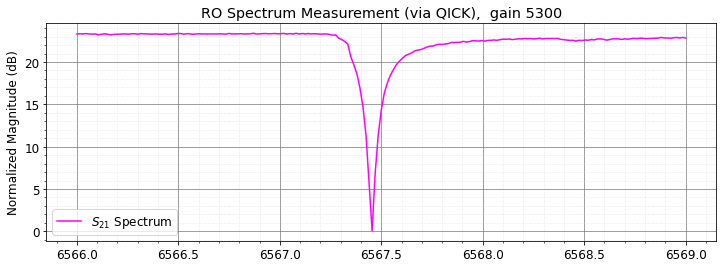

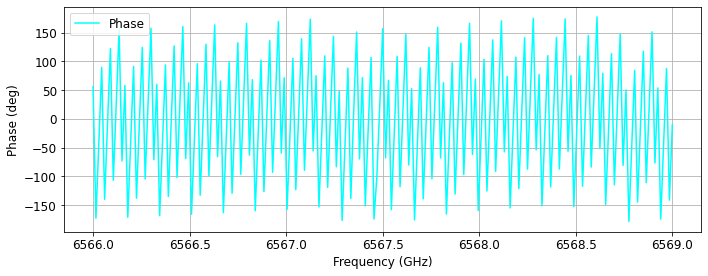

In [6]:
# # Convert raw I/Q data to magnitude and phase
i_data = np.array(i_data)
q_data = np.array(q_data)
magnitude, amplitude_db, phase =[], [], []
magnitude = np.sqrt(i_data**2 + q_data**2)
#amplitude_db = 20 * np.log10(magnitude / np.max(magnitude))  # Normalized Magnitude (dB)
amplitude_db = 20 * np.log10(magnitude)
phase = np.angle(i_data + 1j * q_data, deg=True)

plt.figure(figsize=(12, 4))
plt.plot(frequencies, amplitude_db, color="magenta", label="$S_{21}$ Spectrum")
plt.title(f"RO Spectrum Measurement (via QICK),  gain {config_1tone['gain']}")
plt.ylabel("Normalized Magnitude (dB)")
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.75, color='gray')
plt.grid(which='minor', linestyle=':', linewidth=0.5, color='lightgray')
#plt.grid(True)
plt.legend()
plt.show()
plt.subplots(1,1, figsize=(10, 4))
plt.plot(frequencies, phase, color="cyan", label="Phase")
plt.xlabel("Frequency (GHz)")
plt.ylabel("Phase (deg)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

      LORENTZIAN DIP FIT RESULTS
Resonance Freq (f0) : 6567.4787 +/- 0.0040 MHz
Linewidth (kappa)   : 0.2073 +/- 0.0129 MHz
Loaded Q (Q_L)      : 31683.83 +/- 1964.65


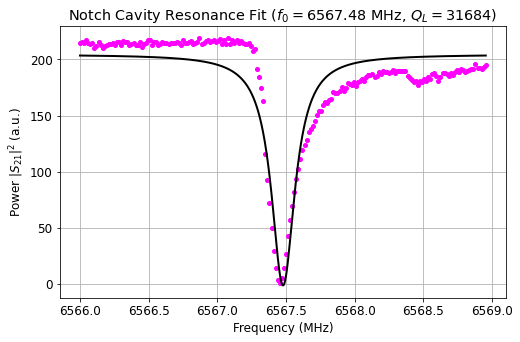

In [7]:
f0, kappa, Q_L = fit_cavity_lorentzian(frequencies, i_data, q_data, fit_range_mhz=3.0)

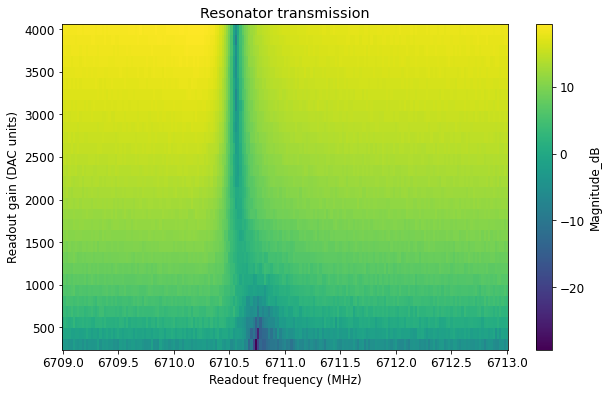

In [37]:
# --- Sweep axes ---
frequencies = np.linspace(6709, 6713, 201)                 # MHz
gains = np.linspace(300, 4000, 30).astype(int)                 # raw DAC gain values

config_pw = {
    "dac_ch": 1,
    "adc_ch": 0,
    "pulse_length": 100.0,     # us
    "readout_length": 99.8,    # us
    "adc_trig_offset": 0.2,    # us
    "reps": 800,
}

# --- Acquire ---
i_map = np.zeros((len(gains), len(frequencies)))
q_map = np.zeros((len(gains), len(frequencies)))

for gi, g in enumerate(tqdm(gains, desc="Gain sweep")):
    config_pw["gain"] = int(g)
    for fi, f in enumerate(frequencies):
        config_pw["freq"] = f
        prog = TransmissionSweepProgram(soccfg, config_pw)
        i_res, q_res = prog.acquire(soc, load_pulses=True, progress=False)
        i_map[gi, fi] = i_res[0][0]
        q_map[gi, fi] = q_res[0][0]

# --- Process: magnitude in dB, drive amplitude divided out, baseline of each row = 0 dB ---
mag = np.abs(i_map + 1j * q_map)
mag_db = 20 * np.log10(mag)
#mag_db -= mag_db.max(axis=1, keepdims=True)


plt.figure(figsize=(10, 6))
pcm = plt.pcolormesh(frequencies, gains, mag_db, shading="nearest", cmap="viridis")
plt.colorbar(pcm, label="Magnitude_dB")
#plt.plot(f0_list, gains, "r.-", label="Fitted $f_0$")
plt.xlabel("Readout frequency (MHz)")
plt.ylabel("Readout gain (DAC units)")
plt.title("Resonator transmission")
#plt.legend()
plt.show()

In [44]:
gains

array([ 300,  427,  555,  682,  810,  937, 1065, 1193, 1320, 1448, 1575,
       1703, 1831, 1958, 2086, 2213, 2341, 2468, 2596, 2724, 2851, 2979,
       3106, 3234, 3362, 3489, 3617, 3744, 3872, 4000])

Qubit spectroscopy (Two-Tone)

In [8]:
class TwoToneSpectroscopyProgram(AveragerProgram):
    def initialize(self):
        cfg = self.cfg
        
        
       
        
        # 1. Channel aliases
        self.res_ch = cfg["res_ch"]
        self.qubit_ch = cfg["qubit_ch"]
        self.adc_ch = cfg["adc_ch"]
        
        self.declare_gen(self.res_ch, nqz=2)
        nqz_q = 1 if cfg["qubit_freq"] < (self.soccfg['gens'][cfg["qubit_ch"]]['fs']/2) else 2
        self.declare_gen(self.qubit_ch, nqz= nqz_q)
        
        # 2. Convert frequencies to registers
        # NOTE: Using cfg["qubit_freq"] so the loop actually updates the tone!
       
        
        # 3. Readout setup
        self.declare_readout(
            ch=self.adc_ch, 
            length=self.us2cycles(cfg["readout_length"], ro_ch=self.adc_ch),
            freq=cfg["res_freq"], 
            gen_ch=self.res_ch
        )
        
        
        res_freq_reg = self.freq2reg(cfg["res_freq"], gen_ch=self.res_ch, ro_ch=self.adc_ch)
        qubit_freq_reg = self.freq2reg(cfg["qubit_freq"], gen_ch=self.qubit_ch)
        
        # 4. Pulse setup
        self.set_pulse_registers(
            ch=self.qubit_ch,
            style="const",
            freq=qubit_freq_reg,
            phase=0,
            gain=cfg["qubit_gain"],
            length=self.us2cycles(cfg["qubit_length"], gen_ch=self.qubit_ch)
        )
        
        self.set_pulse_registers(
            ch=self.res_ch,
            style="const",
            freq=res_freq_reg,
            phase=0,
            gain=cfg["res_gain"],
            length=self.us2cycles(cfg["readout_length"], gen_ch=self.res_ch)
        )
        
        self.synci(200)

    def body(self):
        # Drive qubit
        self.pulse(ch=self.qubit_ch)
        
        self.sync_all(self.us2cycles(0.05))
        
        # Readout
        self.measure(
            pulse_ch=self.res_ch,
            adcs=[self.adc_ch],
            adc_trig_offset=self.us2cycles(self.cfg["adc_trig_offset"],ro_ch=self.adc_ch),
            wait=True,
            syncdelay=self.us2cycles(self.cfg["relax_delay"],gen_ch=self.res_ch)
        )


In [17]:
# ==========================================================
# Configuration & Execution
# ==========================================================
config_2tone = {
    # Hardware Channels
    "res_ch": 1,
    "qubit_ch": 0,
    "adc_ch": 0,
    
    # Readout Setup
    "res_freq": 6567.41,  #6567.42, # 6641.32, #7108.90,                             # mhz
    "res_gain": 5300, #800,      # <-- BUMPED UP from 300 so signal exceeds noise floor!
    "readout_length":40.0,        #us
    "adc_trig_offset": 0.2,  #0.1, # μs
    
    # Qubit Frequency Sweep Setup
    "start_qubit_freq": 3795,                                                          
    "step_qubit_freq": 0.1,     # Step size (MHz)
    "expts": 100,               # 250 steps -> 3340 MHz to 3390 MHz
    "qubit_gain": 1600,      # Increased drive power for clear saturation
    "qubit_length": 40.0,    # μs
    
    # Repetitions
    "reps": 2000,
#     "soft_avgs":1000,
    "relax_delay": 0,
}




frequencies = config_2tone["start_qubit_freq"] + np.arange(config_2tone["expts"]) * config_2tone["step_qubit_freq"]

i_data, q_data = [], []



print("Starting frequency sweep...")
for freq in frequencies:
    config_2tone["qubit_freq"] = freq  # FIX: Pass current frequency into config!
    
    prog = TwoToneSpectroscopyProgram(soccfg, config_2tone)
    i_res, q_res = prog.acquire(soc, load_pulses=True, progress=False)
    
    # Extract IQ averages for ADC 0
    i_data.append(i_res[0][0])
    q_data.append(q_res[0][0])

print("Sweep Complete.")

magnitude, phase, magnitude_db =[],[],[]
# Calculate Magnitude
magnitude = np.abs(np.array(i_data) + 1j * np.array(q_data))
phase = np.angle(np.array(i_data) + 1j *np.array(q_data), deg=True)
magnitude_db = 20 * np.log10(magnitude) 


Starting frequency sweep...
Sweep Complete.


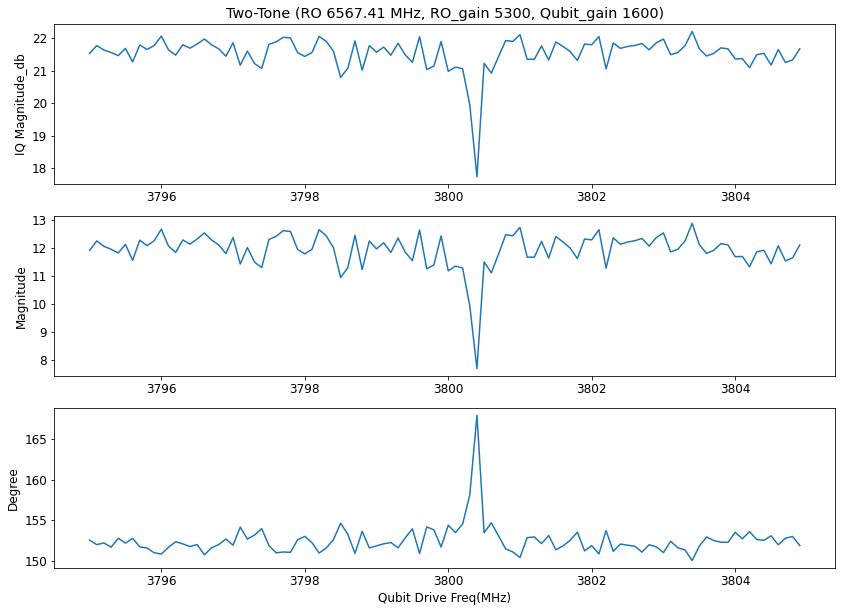

In [18]:
fig, axs = plt.subplots(3, 1, figsize=(14, 10))
axs[0].plot(frequencies, magnitude_db, '-')
axs[0].set_ylabel("IQ Magnitude_db")
#axs[0].set_ylim([-25,0])
axs[0].set_title(f"Two-Tone (RO {config_2tone['res_freq']} MHz, RO_gain {config_2tone['res_gain']}, Qubit_gain {config_2tone['qubit_gain']})")

# axs[1].plot(frequencies, phase, '-')
# axs[1].set_xlabel("Qubit Drive Freq(MHz)")
# axs[1].set_ylabel('Degree')

axs[1].plot(frequencies, magnitude, '-')
#axs[1].set_xlabel("Qubit Drive Freq(MHz)")
axs[1].set_ylabel('Magnitude')

axs[2].plot(frequencies, phase, '-')
axs[2].set_xlabel("Qubit Drive Freq(MHz)")
axs[2].set_ylabel('Degree')

plt.show()

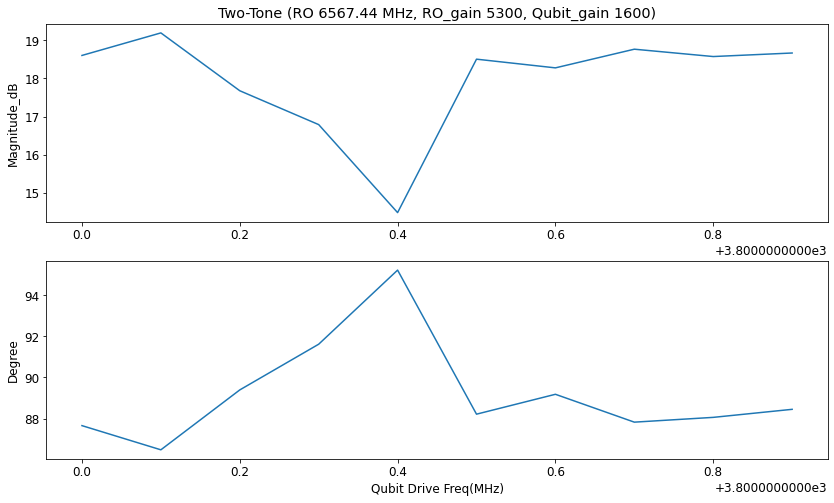

In [106]:
l0, r0 =50, 60
fig, axs = plt.subplots(2, 1, figsize=(14, 8))
axs[0].plot(frequencies[l0:r0], magnitude_db[l0:r0], '-')
axs[0].set_ylabel("Magnitude_dB")
axs[0].set_title(f"Two-Tone (RO {config_2tone['res_freq']} MHz, RO_gain {config_2tone['res_gain']}, Qubit_gain {config_2tone['qubit_gain']})")

axs[1].plot(frequencies[l0:r0], phase[l0:r0], '-')
axs[1].set_xlabel("Qubit Drive Freq(MHz)")
axs[1].set_ylabel('Degree')

plt.show()

# General Config

In [37]:
hw_cfg={#"jpa_ch":6,
        "res_ch":1,
        "qubit_ch":0,
        "ro_ch":0
       }


readout_cfg={
    "readout_length":40,   # us
    "f_res":  6567.43, #6641.32, #6640.80, # 6710.75, #6567.44, #6567.97, # [MHz]
    #"res_phase": 0,
    "adc_trig_offset": 150, # [Clock ticks]
    "res_gain": 5300 #800 #5000 #700 #1550
    }


# Single Shot

In [27]:
class SingleShotProgram(AveragerProgram):
    def initialize(self):
        cfg=self.cfg
        
        self.declare_gen(ch=cfg["res_ch"], nqz=2) #Readout
        self.declare_gen(ch=cfg["qubit_ch"], nqz=1) #Qubit
        self.declare_readout(ch=cfg['ro_ch'], length=self.us2cycles(cfg["readout_length"], ro_ch=cfg["ro_ch"]),
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"])

        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=cfg['ro_ch']) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])
        
        # add qubit and readout pulses to respective channels
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="const", freq=f_ge, phase=0, gain=cfg["qubit_gain"], 
                                 length=cfg["pulse_length"])
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", freq=f_res, phase=cfg["res_phase"], gain=cfg["res_gain"], 
                                 length=self.us2cycles(cfg["readout_length"], gen_ch = cfg['res_ch']))

        self.sync_all(self.us2cycles(500))
    
    def body(self):
        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.sync_all(self.us2cycles(0.05)) # align channels and wait 50ns

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[0],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))
    

In [41]:
expt_cfg_e={"qubit_gain":20000,
          "reps":1,
          "res_phase":0
       }

qubit_cfg={
    #"sigma":soccfg.us2cycles(0.125, gen_ch=0),
    "pulse_length": soccfg.us2cycles(0.115, gen_ch = 0), # 2.5
    #"pi_gain": 20000,
    # "pi2_gain":11500//2, 
    "f_ge":3800.40, #3952.5,  #3800.45,
    "relax_delay":1000
}

config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg_e} #combine configs

di0_e, dq0_e =[],[]
ssp=SingleShotProgram(soccfg, config)

for i in tqdm(np.arange(1000)):
    di0, dq0 = ssp.acquire(soc,progress=False)
    di0_e.append(di0[0][0])
    dq0_e.append(dq0[0][0])
    
expt_cfg_g={"qubit_gain":0,
          "reps":1,
          "res_phase":0
       }

# config={**hw_cfg,**readout_cfg,**expt_cfg_g} #combine configs

config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg_g} #combine configs

di0_g, dq0_g =[],[]
ssp=SingleShotProgram(soccfg, config)

for i in tqdm(np.arange(1000)):
    di0, dq0 = ssp.acquire(soc,progress=False)
    di0_g.append(di0[0][0])
    dq0_g.append(dq0[0][0])



  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

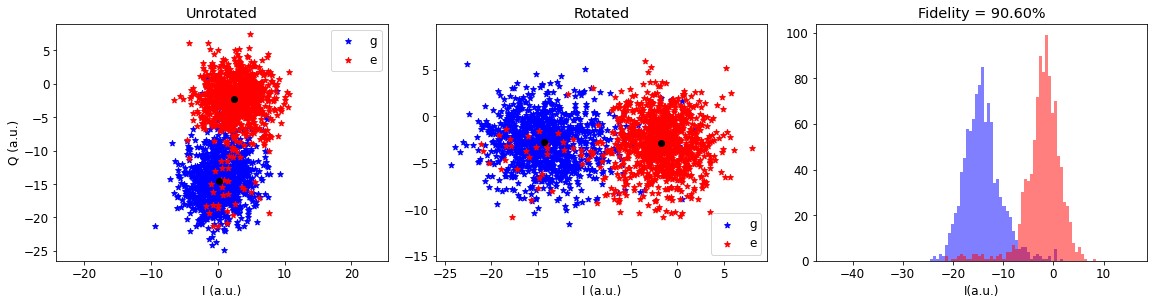

In [42]:
fid, threshold, angle = hist(data=[di0_g, dq0_g, di0_e, dq0_e],  plot=True, ran=30)

#print('Optimal fidelity after rotation = %.3f' % fid)
readout_cfg["res_phase"]=soccfg.deg2reg(-angle*180/np.pi, gen_ch=1)
readout_cfg["threshold"]=round(threshold)

In [43]:
print(readout_cfg['res_phase'])
print(readout_cfg['threshold'])

954770595
-8


# Length Rabi

In [28]:
class LengthRabiProgram(AveragerProgram):
    def initialize(self):
        cfg=self.cfg

        self.declare_gen(ch=cfg["res_ch"], nqz=2) #Readout
        self.declare_gen(ch=cfg["qubit_ch"], nqz=1) #Qubit
        #for ch in [0,1]: #configure the readout lengths and downconversion frequencies
        # self.declare_readout(ch=cfg['ro_ch'], length=cfg["readout_length"],
        #                          freq=cfg["f_res"], gen_ch=cfg["res_ch"])
        
        self.declare_readout(ch=cfg['ro_ch'], length=self.us2cycles(cfg["readout_length"], ro_ch=cfg["ro_ch"]),
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"])
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=cfg['ro_ch']) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])
        


        # add qubit and readout pulses to respective channels
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="const", freq=f_ge, phase=0, gain=cfg["qubit_gain"], 
                                 length=cfg["pulse_length"])
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", freq=f_res, phase=cfg["res_phase"], gain=cfg["res_gain"], 
                                 length=self.us2cycles(cfg["readout_length"], gen_ch = cfg['res_ch']))

        self.synci(200)
        
    def body(self):
        cfg=self.cfg
        self.pulse(ch=cfg["qubit_ch"])  #play probe pulse
        self.sync_all(self.us2cycles(0.0)) # align channels and wait 50ns

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=cfg["res_ch"], 
             adcs=[cfg['ro_ch']],
             adc_trig_offset=cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(cfg["relax_delay"]))

In [29]:
expt_cfg={
       "qubit_gain":20000,
        "start":3, "step":10, "expts":50, "reps": 800,
       }
# Pulse length varies in clock ticks in generator channel,fabric=614.400 MHz,  1 cltks = 1/(614.4 MHz) ~ 1.6276 ns   
# Time length varies for generator or readout channel, 


qubit_cfg={
    #"sigma":soccfg.us2cycles(0.025, gen_ch=2),
    # "pi_gain": 11500,
    # "pi2_gain":11500//2, 
    "f_ge": 3800.40, #3189, #3262.45, # 3952.5, #3800.45,
    "relax_delay":1000
}

config_TR={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs
expt_pts=[expt_cfg["start"] + ii*expt_cfg["step"] for ii in range(expt_cfg["expts"])]

In [30]:
i_data, q_data = [], []

if "res_phase" in config_TR:
    print('res_phase calibrated')
else:
    config_TR["res_phase"] = 0
    
for length in tqdm(expt_pts):                   # tqdm is a Python library that provides a fast, extensible progress bar for loops and other iterable objects.
    config_TR["pulse_length"]=length

    rabi=LengthRabiProgram(soccfg, config_TR)
    i_res,q_res = rabi.acquire(soc, threshold=readout_cfg["threshold"], progress=False)
    # Extract IQ averages for ADC 0
    i_data.append(i_res[0][0])
    q_data.append(q_res[0][0])
    
# Calculate Magnitude
magnitude = np.abs(np.array(i_data) + 1j * np.array(q_data))
phase = np.angle(np.array(i_data) + 1j *np.array(q_data), deg=True)
magnitude_db = 20 * np.log10(magnitude) 
time_s = soccfg.cycles2us(np.array(expt_pts), gen_ch=0)*1000

res_phase calibrated


  0%|          | 0/50 [00:00<?, ?it/s]

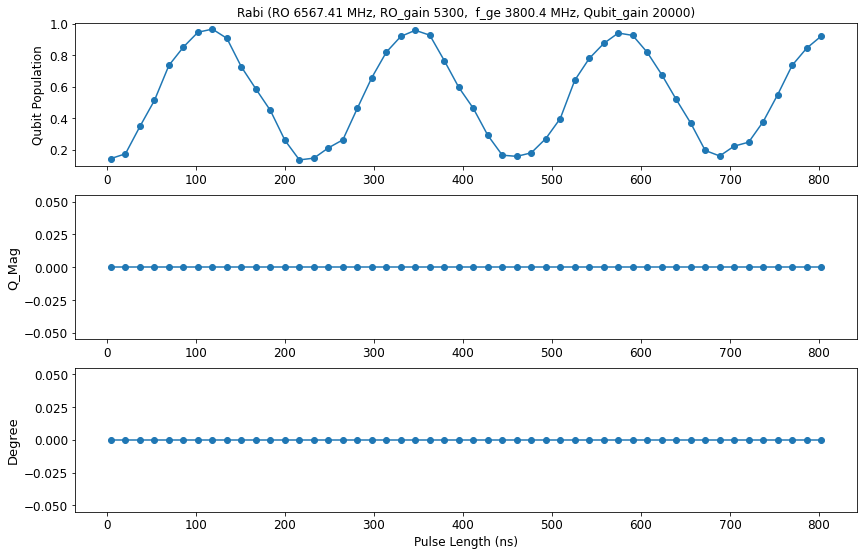

In [31]:
fig, axs = plt.subplots(3, 1, figsize=(14, 9))
axs[0].plot(time_s, i_data,'o-')
axs[0].set_ylabel("Qubit Population", fontsize =12)

axs[0].set_title(f"Rabi (RO {config_TR['f_res']} MHz, RO_gain {config_TR['res_gain']},  f_ge {config_TR['f_ge']} MHz, Qubit_gain {config_TR['qubit_gain']})", fontsize = 12)

axs[1].plot(time_s, q_data,'o-')
axs[1].set_ylabel(f"Q_Mag", fontsize = 13)

axs[2].plot(time_s, phase, 'o-')
axs[2].set_xlabel(f"Pulse Length (ns)")
axs[2].set_ylabel('Degree', fontsize = 13)

plt.show()

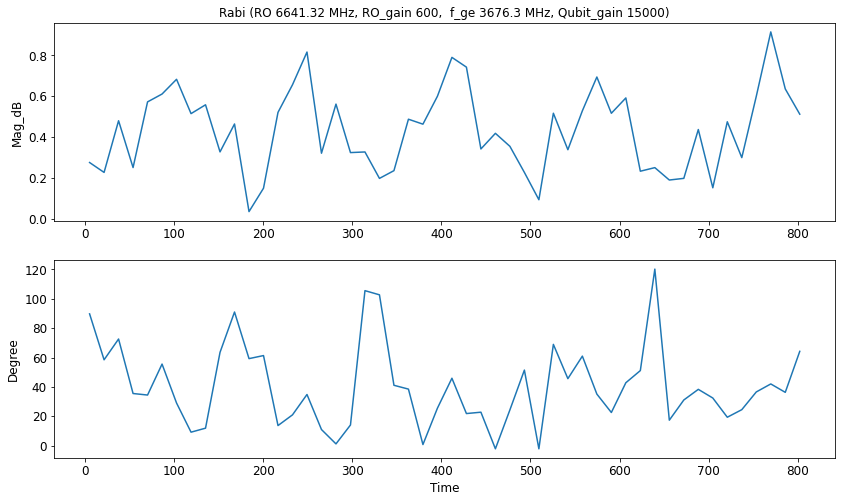

In [80]:
fig, axs = plt.subplots(2, 1, figsize=(14, 8))
axs[0].plot(time_s, magnitude, '-')
axs[0].set_ylabel("Mag_dB")
axs[0].set_title(f"Rabi (RO {config_TR['f_res']} MHz, RO_gain {config_TR['res_gain']},  f_ge {config_TR['f_ge']} MHz, Qubit_gain {config_TR['qubit_gain']})", fontsize = 12)
axs[1].plot(time_s, phase, '-')
axs[1].set_xlabel("Time")
axs[1].set_ylabel('Degree')

plt.show()

In [32]:
# -----------------------------------------------------------------------------
# 2. Define Fitting Function (Damped Cosine Model)
# y(t) = A * cos(2 * pi * f * t + phi) * exp(-t / tau) + offset
# -----------------------------------------------------------------------------
def rabi_model(t, A, f, phi, tau, offset):
    return A * np.cos(2 * np.pi * f * t + phi) * np.exp(-t / tau) + offset

# Alternative simple model without decay if decay is negligible:
def simple_rabi_model(t, A, f, phi, offset):
    return A * np.cos(2 * np.pi * f * t + phi) + offset

In [33]:
A_guess = (np.max(i_data) - np.min(i_data)) / 2.0
offset_guess = np.mean(i_data)
f_guess = 1.0 / 200.0  # Approx frequency in GHz (1/ns)
phi_guess = np.pi       # Plot starts near minimum (~ -14)
tau_guess = 1000.0      # Large initial guess for decay constant T_2*

p0 = [A_guess, f_guess, phi_guess, offset_guess]

In [34]:
# -----------------------------------------------------------------------------
# 4. Perform Curve Fit
# -----------------------------------------------------------------------------
popt, pcov = curve_fit(simple_rabi_model, time_s, i_data, p0=p0)
perr = np.sqrt(np.diag(pcov))  # 1-sigma standard uncertainties

# Extract parameters
A_fit, f_fit, phi_fit, offset_fit = popt
A_err, f_err, phi_err, offset_err = perr

# Calculate Rabi Period (T_rabi = 1 / f_rabi)
# Enforce positive frequency
f_fit = abs(f_fit)
period = 1.0 / f_fit
period_err = f_err / (f_fit**2)

# Convert frequency to MHz for readability (since time is in ns: 1 / ns = 1 GHz = 1000 MHz)
freq_MHz = f_fit * 1e3
freq_MHz_err = f_err * 1e3

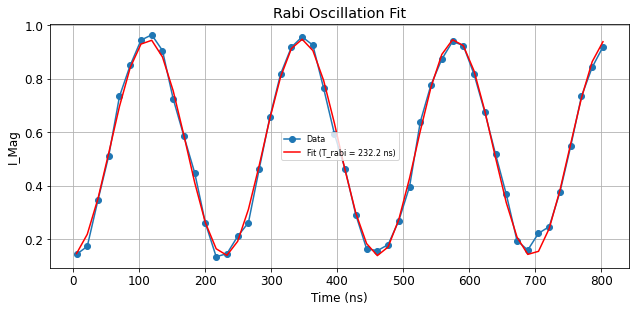

In [35]:
#t_dense = np.linspace(min(x_data), max(x_data), 500)
y_fit = simple_rabi_model(time_s, *popt)

plt.figure(figsize=(9, 4.5))
plt.plot(time_s, i_data, 'o-', label='Data')
plt.plot(time_s, y_fit, 'r-', label=f'Fit (T_rabi = {period:.1f} ns)')
plt.xlabel('Time (ns)')
plt.ylabel('I_Mag')
plt.title('Rabi Oscillation Fit')
plt.legend(fontsize = 8)
plt.grid(True)
plt.tight_layout()
plt.show()

In [244]:
print(f"--- Fitting Results ---")
print(f"Rabi Frequency (f): {freq_MHz:.3f} +/- {freq_MHz_err:.3f} MHz")
print(f"Rabi Period (T)   : {period:.2f} +/- {period_err:.2f} ns")
#print(f"Decay Time (tau)  : {tau_fit:.2f} +/- {tau_err:.2f} ns")
print(f"Amplitude         : {abs(A_fit):.3f} +/- {A_err:.3f}")
print(f"Offset            : {offset_fit:.3f} +/- {offset_err:.3f}")

--- Fitting Results ---
Rabi Frequency (f): 9.943 +/- 0.014 MHz
Rabi Period (T)   : 100.58 +/- 0.14 ns
Amplitude         : 2.067 +/- 0.041
Offset            : -4.046 +/- 0.029


# Chevron plot (drive detunning)

In [34]:
qubit_cfg={
    #"sigma":soccfg.us2cycles(0.025, gen_ch=2),
    # "pi_gain": 11500,
    # "pi2_gain":11500//2, 
    #"f_ge":3800.45,
    "relax_delay":1000
}
expt_cfg={
       "qubit_gain":20000,
        "start":3, "step":10, "expts":50, "reps": 400,
       }
Drive_freq = np.arange(3798,3803,0.1, dtype = float)

In [35]:
config_TR={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs
expt_pts=[expt_cfg["start"] + ii*expt_cfg["step"] for ii in range(expt_cfg["expts"])]

In [36]:
i_data_che = np.zeros((len(Drive_freq), len(expt_pts)))

In [37]:
np.shape(i_data_che)

(50, 50)

In [40]:
print("Starting 2D Rabi Chevron Sweep...")
for i, freq in tenumerate(Drive_freq):
    config_TR['f_ge'] = freq
    for j, length in enumerate(expt_pts):
        config_TR['pulse_length'] = length
        
        rabi=LengthRabiProgram(soccfg, config_TR)
        i_res,q_res = rabi.acquire(soc, progress=False)
        
        i_data_che[i,j] = i_res[0][0]

print("Sweep Complete!")

Starting 2D Rabi Chevron Sweep...


  0%|          | 0/50 [00:00<?, ?it/s]

Sweep Complete!


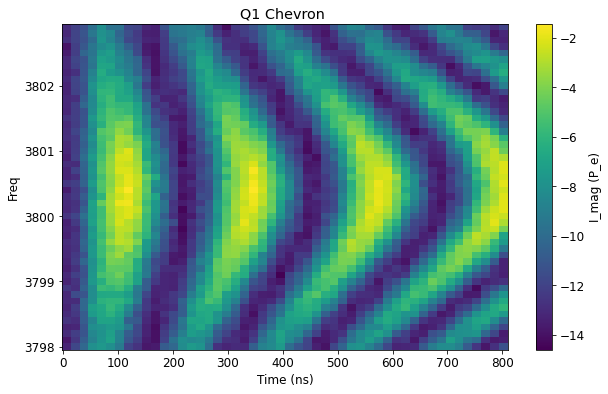

In [45]:
time_s = soccfg.cycles2us(np.array(expt_pts), gen_ch=0)*1000
plt.figure(figsize=(10, 6))
pcm = plt.pcolormesh(time_s, Drive_freq, i_data_che, shading="nearest", cmap="viridis")
plt.colorbar(pcm, label="I_mag (P_e)")
#plt.plot(f0_list, gains, "r.-", label="Fitted $f_0$")
plt.xlabel("Time (ns)")
plt.ylabel("Freq")
plt.title("Q1 Chevron ")
#plt.legend()
plt.show()

In [43]:
sdate = '26_10_05'                             # Date the data is saved 
save_dir= Path(f"Lab_Data/{sdate}")
save_dir.mkdir(parents = True, exist_ok=True)

In [107]:
#Time_IQ = np.transpose(np.array([i_data,q_data]))
#np.shape(Time_IQ)


(50, 2)

In [48]:
filename_iq = f"Q1_Chevron.csv"
filepath_iq = save_dir/filename_iq
#df = pd.DataFrame(Time_IQ, index = Time_step)
df = pd.DataFrame(i_data_che, index=Drive_freq, columns=time_s)
# df.index.name = "Drive_freq"
# df.columns.name = "Time (ns)"
df.to_csv(filepath_iq, index = True)

In [109]:
file_path = save_dir / "parameters_TRabi0.json"
print(file_path)
params = config_TR.copy()
with open(file_path, "w") as file: # SAVE Measurement Params to file
    json.dump(params, file, indent=4)

Lab_Data/26_09_18/parameters_TRabi0.json


# Power Rabi

In [10]:
class AmplitudeRabiProgram(RAveragerProgram):
    def initialize(self):
        cfg=self.cfg
        
        self.q_rp=self.ch_page(self.cfg["qubit_ch"])     # get register page for qubit_ch
        self.r_gain=self.sreg(cfg["qubit_ch"], "gain")   # get gain register for qubit_ch    
        
        self.declare_gen(ch=cfg["res_ch"], nqz=2) #Readout
        self.declare_gen(ch=cfg["qubit_ch"], nqz=1) #Qubit
        
        self.declare_readout(ch=cfg['ro_ch'], length=self.us2cycles(cfg["readout_length"], ro_ch=cfg["ro_ch"]),
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"])
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=cfg['ro_ch']) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])

        # add qubit and readout pulses to respective channels
        # self.add_gauss(ch=cfg["qubit_ch"], name="qubit", sigma=cfg["sigma"], length=cfg["sigma"]*4)
#         self.set_pulse_registers(ch=cfg["qubit_ch"], style="arb", freq=f_ge, phase=self.deg2reg(90, gen_ch=cfg["qubit_ch"]), gain=cfg["start"], 
#                                  waveform="qubit")

    
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="const", freq=f_ge, phase=0, gain=cfg["start"], 
                                 length=cfg["pulse_length"])
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", freq=f_res, phase=cfg["res_phase"], gain=cfg["res_gain"], 
                                 length=self.us2cycles(cfg["readout_length"], gen_ch = cfg['res_ch']))
        
        self.sync_all(self.us2cycles(500))
    
    def body(self):
        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.sync_all(self.us2cycles(0.05)) # align channels and wait 50ns

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[self.cfg['ro_ch']],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))
    
    def update(self):
        self.mathi(self.q_rp, self.r_gain, self.r_gain, '+', self.cfg["step"]) # update gain of the Gaussian pi pulse

In [11]:
expt_cfg={
        "start":0, "step":300, "expts":100, "reps": 700
       }

# hw_cfg={#"jpa_ch":6,
#         "res_ch":1,
#         "qubit_ch":0,
#         "ro_ch":0
#        }



# readout_cfg={
#     "readout_length":40,   # us
#     "f_res": 6567.44,   #6567.97,             #7108.9, # [MHz]
#     "res_phase": 3396314095,
#     "adc_trig_offset": 150, # [Clock ticks]
#     "res_gain":5300
#     }
qubit_cfg={
    #"sigma":soccfg.us2cycles(0.025, gen_ch=2),
    # "pi_gain": 11500,
    # "pi2_gain":11500//2, 
    "pulse_length": soccfg.us2cycles(0.115, gen_ch=0),
    "f_ge":3800.40,
    "relax_delay":1000,
}

config_AR={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs

rabi=AmplitudeRabiProgram(soccfg, config_AR)
x_pts, avgi, avgq  = rabi.acquire(soc,progress=True)

KeyError: 'res_phase'

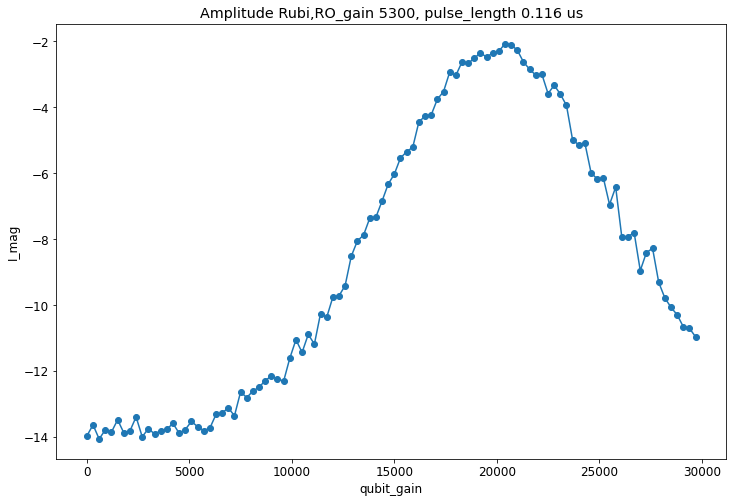

In [28]:

fig, axs = plt.subplots(1,1,)     # figsize = [14,10])
axs.plot(x_pts,avgi[0][0],'o-')
axs.set_title(f'Amplitude Rubi,RO_gain {config_AR["res_gain"]}, pulse_length {np.round(soccfg.cycles2us(config_AR["pulse_length"],gen_ch=0), decimals =3)} us')
axs.set_xlabel(f'qubit_gain')
axs.set_ylabel(f'I_mag')
plt.show()



In [101]:
Amp_IQ = np.transpose(np.array([avgi[0][0],avgq[0][0]]))
filename_Aiq = f"Amp_Rabi_IQ_0.csv"
filepath_Aiq = save_dir/filename_Aiq
df = pd.DataFrame(Amp_IQ, index = x_pts)

df.to_csv(filepath_Aiq, index = True)

In [110]:

file_path = save_dir / "parameters_ARabi0.json"
print(file_path)
params = config.copy()
with open(file_path, "w") as file: # SAVE Measurement Params to file
    json.dump(params, file, indent=4)

Lab_Data/26_09_18/parameters_ARabi0.json


# T1 measure

In [45]:
class T1Program(RAveragerProgram):
    def initialize(self):
        cfg=self.cfg
        
        self.q_rp=self.ch_page(cfg["qubit_ch"])     # get register page for qubit_ch
        self.r_wait = 3           # default register number to store pulse play start time
        self.regwi(self.q_rp, self.r_wait, cfg["start"])

        self.declare_gen(ch=cfg["res_ch"], nqz=2) #Readout
        self.declare_gen(ch=cfg["qubit_ch"], nqz=1) #Qubit
       
        self.declare_readout(ch=cfg['ro_ch'], length=self.us2cycles(cfg["readout_length"], ro_ch=cfg["ro_ch"]),
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"])
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=cfg['ro_ch']) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])

        # add qubit and readout pulses to respective channels
        # self.add_gauss(ch=cfg["qubit_ch"], name="qubit", sigma=cfg["sigma"], length=cfg["sigma"]*4)
        # self.set_pulse_registers(ch=cfg["qubit_ch"], style="arb", freq=f_ge, phase=0, gain=cfg["qubit_gain"], 
        #                          waveform="qubit")
        
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="const", freq=f_ge, phase=0, gain=cfg["qubit_gain"], 
                                 length=cfg["pulse_length"])
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", freq=f_res, phase=cfg["res_phase"], gain=cfg["res_gain"], 
                                 length=self.us2cycles(cfg["readout_length"], gen_ch = cfg['res_ch']))

        self.sync_all(self.us2cycles(0.2))
    
    def body(self):
        self.pulse(ch=self.cfg["qubit_ch"])  #play probe pulse
        self.sync_all()
        self.sync(self.q_rp,self.r_wait)

        #trigger measurement, play measurement pulse, wait for qubit to relax
        self.measure(pulse_ch=self.cfg["res_ch"], 
             adcs=[self.cfg['ro_ch']],
             adc_trig_offset=self.cfg["adc_trig_offset"],
             wait=True,
             syncdelay=self.us2cycles(self.cfg["relax_delay"]))
    
    def update(self):
        self.mathi(self.q_rp, self.r_wait, self.r_wait, '+', self.us2cycles(self.cfg["step"])) # update frequency list index

In [46]:
expt_cfg={
       "qubit_gain":20000,
        "start":0, "step":10, "expts":50, "reps": 1000,
       }   # Here step is us !!!!


# Pulse length varies in clock ticks in generator channel,fabric=614.400 MHz,  1 cltks = 1/(614.4 MHz) ~ 1.6276 ns   
# Time length varies for generator or readout channel, 

# hw_cfg={#"jpa_ch":6,
#         "res_ch":1,
#         "qubit_ch":0,
#         "ro_ch":0
#        }


# readout_cfg={
#     "readout_length":40,   # us
#     "f_res": 6567.44, # [MHz]
#     "res_phase": 3396314095,
#     "adc_trig_offset": 150, # [Clock ticks]
#     "res_gain":5300
#     }
qubit_cfg={
    #"sigma":soccfg.us2cycles(0.125, gen_ch=0),
    "pulse_length": soccfg.us2cycles(0.115, gen_ch = 0),
    "pi_gain": 20000,
    # "pi2_gain":11500//2, 
    "f_ge":3800.40,
    "relax_delay":1000
}

config={**hw_cfg,**readout_cfg,**qubit_cfg,**expt_cfg} #combine configs

t1p=T1Program(soccfg, config)

In [48]:
x_pts, avgi, avgq = t1p.acquire(soc,threshold=readout_cfg["threshold"], progress=True)


  0%|          | 0/50000 [00:00<?, ?it/s]

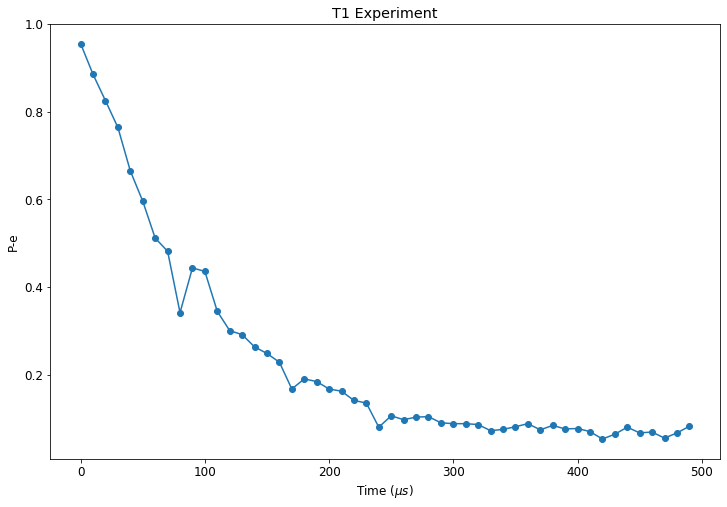

In [49]:
plt.subplot(111, title="T1 Experiment", xlabel=f"Time ($\mu s$)", ylabel="P-e")
plt.plot(x_pts, avgi[0][0],'o-');
#plt.plot(x_pts, avgq[0][0],'.-');

In [50]:
avgi[0][0][-1]

0.083

In [262]:
def t1_model(t, A, T1, offset):
    return A * np.exp(-t / T1) + offset

In [263]:
offset_guess = avgi[0][0][-10:].mean()          # Baseline asymptotic value (~ -14.5)
A_guess = avgi[0][0][0] - offset_guess          # Initial amplitude (~ 12.8)
T1_guess = 100.0                            # Initial T1 guess in \mu s

p0 = [A_guess, T1_guess, offset_guess]

In [264]:
popt, pcov = curve_fit(t1_model, x_pts, avgi[0][0], p0=p0)
perr = np.sqrt(np.diag(pcov))  # Standard 1-sigma errors

A_fit, T1_fit, offset_fit = popt
A_err, T1_err, offset_err = perr

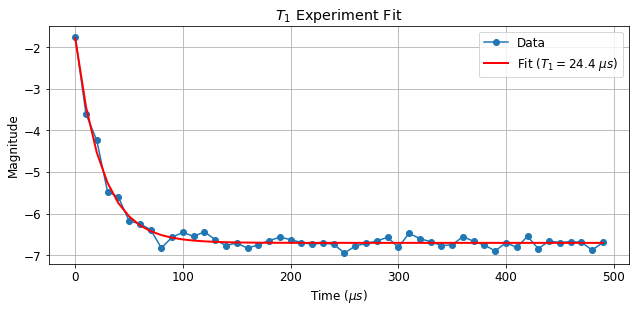

In [265]:
#t_dense = np.linspace(min(x_data), max(x_data), 500)
y_fit = t1_model(x_pts, *popt)

plt.figure(figsize=(9, 4.5))
plt.plot(x_pts, avgi[0][0], 'o-', label='Data')
plt.plot(x_pts, y_fit, 'r-', linewidth=2, label=f'Fit ($T_1 = {T1_fit:.1f}\\ \\mu s$)')
plt.xlabel(r'Time ($\mu s$)')
plt.ylabel('Magnitude')
plt.title(r'$T_1$ Experiment Fit')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Ramsey Pulse (T2*)

In [17]:

# --- 1. QICK Ramsey Program Definition ---
class RamseyProgram_v1(AveragerProgram):
    def initialize(self):
#         cfg = self.cfg
        
#         # Declare Generator Channels (nqz=2 for resonator around ~7 GHz, nqz=1 for qubit around ~4-5 GHz)
#         self.declare_gen(ch=cfg["res_ch"], nqz=cfg.get("res_nqz", 2)) 
#         self.declare_gen(ch=cfg["qubit_ch"], nqz=cfg.get("qubit_nqz", 1)) 
        
#         # Declare Readout ADC Channel
#         self.declare_readout(
#             ch=cfg['ro_ch'], 
#             length=self.us2cycles(cfg["readout_length"], ro_ch=cfg["ro_ch"]),
#             freq=cfg["f_res"], 
#             gen_ch=cfg["res_ch"]
#         )

#         f_res = self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=cfg['ro_ch'])
#         f_ge  = self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])
        
        cfg=self.cfg

        self.declare_gen(ch=cfg["res_ch"], nqz=2) #Readout
        self.declare_gen(ch=cfg["qubit_ch"], nqz=1) #Qubit
        #for ch in [0,1]: #configure the readout lengths and downconversion frequencies
        # self.declare_readout(ch=cfg['ro_ch'], length=cfg["readout_length"],
        #                          freq=cfg["f_res"], gen_ch=cfg["res_ch"])
        
        self.declare_readout(ch=cfg['ro_ch'], length=self.us2cycles(cfg["readout_length"], ro_ch=cfg["ro_ch"]),
                                 freq=cfg["f_res"], gen_ch=cfg["res_ch"])
        
        f_res=self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=cfg['ro_ch']) # conver f_res to dac register value
        f_ge=self.freq2reg(cfg["f_ge"], gen_ch=cfg["qubit_ch"])
        self.f_ge_reg = f_ge             # store this to use in body
#         # Configure Readout Pulse Register
#         self.set_pulse_registers(
#             ch=cfg["res_ch"], style="const", freq=f_res, 
#             phase=cfg["res_phase"], gain=cfg["res_gain"], 
#             length=self.us2cycles(cfg["readout_length"], gen_ch=cfg['res_ch'])
#         )

#         # Configure Qubit Drive Register for Initial pi/2 Pulse
#         # pi/2 pulse amplitude is set to pi_gain // 2 (or a calibrated pi_half_gain)
#         self.set_pulse_registers(
#             ch=cfg["qubit_ch"], style="const", freq=f_ge, 
#             phase=0, gain=cfg["pi_gain"] // 2, 
#             length=self.us2cycles(cfg["pulse_length"], gen_ch=cfg['qubit_ch'])
#         )
        
        # add qubit and readout pulses to respective channels
        self.set_pulse_registers(ch=cfg["qubit_ch"], style="const", freq=f_ge, phase=0, gain=cfg["pi2_gain"], 
                                 length=cfg["pulse_length"])
        self.set_pulse_registers(ch=cfg["res_ch"], style="const", freq=f_res, phase=cfg["res_phase"], gain=cfg["res_gain"], 
                                 length=self.us2cycles(cfg["readout_length"], gen_ch = cfg['res_ch']))
#       self.sync_all(self.us2cycles(500))

        self.sync_all(self.us2cycles(500)) # Thermalization relaxation before body
    
    def body(self):
        cfg = self.cfg
        
        # Calculate Phase for Artificial Detuning Fringes:
        # Phase (deg) = 360 * (f_detuning [MHz] * wait_time [us])
        phase_deg = 360 * (cfg["f_detuning"] * cfg["wait_time"])
        phase_reg = self.deg2reg(phase_deg, gen_ch=cfg["qubit_ch"])

        # 1. First pi/2 pulse (creates superposition state)
        self.set_pulse_registers(
            ch=cfg["qubit_ch"], style="const",
            freq=self.f_ge_reg, phase=0, gain=cfg["pi2_gain"],
            length=cfg["pulse_length"]
        )
        self.pulse(ch=cfg["qubit_ch"])  
        self.sync_all()
        # 2. Variable Ramsey Delay time (tau)
        if cfg["wait_time"] > 0:
            self.sync_all(self.us2cycles(cfg["wait_time"]))
            
        # 3. Second pi/2 pulse with phase offset applied
        self.set_pulse_registers(
            ch=cfg["qubit_ch"], style="const", 
            freq=self.f_ge_reg, 
            phase=phase_reg, gain=cfg["pi2_gain"] , 
            length=cfg["pulse_length"]
        )
        self.pulse(ch=cfg["qubit_ch"])
        self.sync_all(self.us2cycles(0.05))

        # 4. Measure Resonator & Readout Qubit State
        self.measure(
            pulse_ch=cfg["res_ch"], 
            adcs=[cfg["ro_ch"]],
            adc_trig_offset=cfg["adc_trig_offset"],
            wait=True,
            syncdelay=self.us2cycles(cfg["relax_delay"])
        )



In [19]:
# --- 2. Ramsey Sweep Execution ---
# Configure Ramsey delay sweep range: e.g., 0 to 20 us
delay_times = np.linspace(0, 40, 101)  # Array of wait times tau (µs)


qubit_cfg={
    #"sigma":soccfg.us2cycles(0.125, gen_ch=0),
    "qubit_gain": 20000,   # check power Rabi for Pi/2 gain
    "pulse_length": soccfg.us2cycles(0.115, gen_ch = 0), # 2.5
    #"pi_gain": 20000,
    "pi2_gain":14000, 
    "f_ge":3800.40,
    "relax_delay":1000
}
config={**hw_cfg,**readout_cfg,**qubit_cfg}


config["f_detuning"] = 0.2            # 500 kHz artificial detuning for clear fringes
config["reps"] = 2000                  # Hardware averages per point

ro_cycles = soccfg.us2cycles(config["readout_length"], ro_ch=config["ro_ch"])

i_list, q_list = [], []

print("Executing Ramsey Sweep...")
for tau in delay_times:
    config["wait_time"] = tau
    prog = RamseyProgram_v1(soccfg, config)
#    prog.acquire(soc, load_pulses=True, progress=False)
    i_res,q_res = prog.acquire(soc, load_pulses=True, progress=False)
    
    # Store hardware-averaged single I and Q points
#     i_list.append(prog.di_buf[0][0] / ro_cycles)
#     q_list.append(prog.dq_buf[0][0] / ro_cycles)
    i_list.append(i_res[0][0])
    q_list.append(q_res[0][0])
    
print("Ramsey Sweep Completed.")
i_data = np.array(i_list)
q_data = np.array(q_list)



Executing Ramsey Sweep...
Ramsey Sweep Completed.


Fit Complete!
Measured T2*: 20.55 µs
Measured Detuning: 434.06 kHz


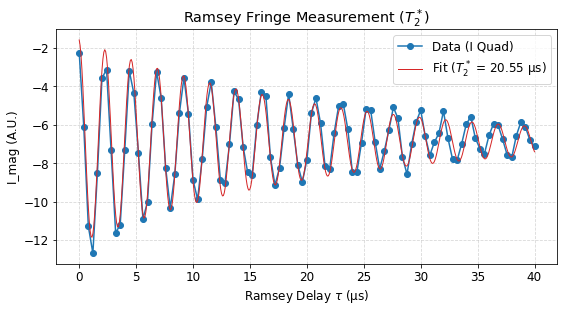

In [20]:
# --- 3. Fit T2* Decaying Sinusoid ---
def ramsey_model(t, A, T2_star, freq, phi, C):
    """ Exponentially decaying cosine wave fit model """
    return A * np.exp(-t / T2_star) * np.cos(2 * np.pi * freq * t + phi) + C

# Initial Guesses: [Amplitude, T2*, Oscillation Freq (MHz), Phase, Offset]
p0 = [(np.max(i_data) - np.min(i_data)) / 2, 1.0, config["f_detuning"], 0, np.mean(i_data)]

try:
    popt, pcov = curve_fit(ramsey_model, delay_times, i_data, p0=p0)
    t2_star_fit = popt[1]
    freq_fit = popt[2]
    print(f"Fit Complete!")
    print(f"Measured T2*: {t2_star_fit:.2f} µs")
    print(f"Measured Detuning: {freq_fit * 1000:.2f} kHz")
except Exception as err:
    print("Fitting failed:", err)
    popt = None

# --- 4. Plotting Results ---
plt.figure(figsize=(8, 4.5))
plt.plot(delay_times, i_data, '-o', label="Data (I Quad)", color="tab:blue", alpha=1)

if popt is not None:
    t_fine = np.linspace(0, delay_times[-1], 500)
    plt.plot(t_fine, ramsey_model(t_fine, *popt), '-', 
             label=f"Fit ($T_2^*$ = {t2_star_fit:.2f} µs)", color="tab:red", linewidth=1)

plt.title("Ramsey Fringe Measurement ($T_2^*$)")
plt.xlabel("Ramsey Delay $\\tau$ (µs)")
plt.ylabel("I_mag (A.U.)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Hahn Echo Pulse

In [30]:

# --- 1. Hahn Echo Program ---
class HahnEchoProgram(AveragerProgram):
    """
    Hahn Echo sequence to measure T2_echo of a transmon qubit.

    Pulse sequence:
        π/2_X  →  τ/2  →  π_Y  →  τ/2  →  π/2_X  →  measure

    The π_Y refocusing pulse brings the Bloch vector back to +Y,
    so the final π/2_X rotates it to |1⟩ for maximum contrast.

    Artificial detuning via virtual-Z phase on the final π/2 pulse
    creates oscillating fringes for a robust T2_echo fit.
    """

    def initialize(self):
        cfg = self.cfg

        # ── Declare channels ──────────────────────────────────────────────
        self.declare_gen(ch=cfg["res_ch"],   nqz=2)  # readout  (~6-7 GHz)
        self.declare_gen(ch=cfg["qubit_ch"], nqz=1)  # qubit    (~3-5 GHz)

        self.declare_readout(
            ch=cfg["ro_ch"],
            length=self.us2cycles(cfg["readout_length"], ro_ch=cfg["ro_ch"]),
            freq=cfg["f_res"],
            gen_ch=cfg["res_ch"]
        )

        # ── Frequency registers ───────────────────────────────────────────
        f_res = self.freq2reg(cfg["f_res"], gen_ch=cfg["res_ch"], ro_ch=cfg["ro_ch"])
        f_ge  = self.freq2reg(cfg["f_ge"],  gen_ch=cfg["qubit_ch"])
        self.f_ge_reg = f_ge   # store for body()

        # ── Pulse lengths in cycles ───────────────────────────────────────
        self.pi2_cycles = self.us2cycles(cfg["pulse_length"],    gen_ch=cfg["qubit_ch"])
        self.pi_cycles  = self.us2cycles(cfg["pi_pulse_length"], gen_ch=cfg["qubit_ch"])

        # ── Readout pulse ─────────────────────────────────────────────────
        self.set_pulse_registers(
            ch=cfg["res_ch"], style="const",
            freq=f_res, phase=cfg["res_phase"], gain=cfg["res_gain"],
            length=self.us2cycles(cfg["readout_length"], gen_ch=cfg["res_ch"])
        )

        # ── Thermalization before first shot ──────────────────────────────
        self.sync_all(self.us2cycles(cfg["relax_delay"]))

    def body(self):
        cfg = self.cfg

        # Artificial detuning: phase accumulates over full τ (not τ/2)
        # Same convention as Ramsey — tracks total free evolution time
        phase_deg = 360.0 * cfg["f_detuning"] * (cfg["wait_time"]/2)
        phase_reg = self.deg2reg(phase_deg, gen_ch=cfg["qubit_ch"])

        # ── 1. First π/2_X pulse (X axis, phase = 0°) ────────────────────
        # Rotates |0⟩ (+Z) → +Y on Bloch sphere
        self.set_pulse_registers(
            ch=cfg["qubit_ch"], style="const",
            freq=self.f_ge_reg,
            phase=self.deg2reg(0, gen_ch=cfg["qubit_ch"]),
            gain=cfg["pi2_gain"],
            length=self.pi2_cycles
        )
        self.pulse(ch=cfg["qubit_ch"])
        self.sync_all()                                    # wait for pulse to finish

        # ── 2. Free evolution τ/2 ─────────────────────────────────────────
        # Bloch vector precesses by Δf_real · τ/2
        self.sync_all(self.us2cycles(cfg["wait_time"] / 2))

        # ── 3. π_Y refocusing pulse (Y axis, phase = 90°) ────────────────
        # Flips X component, preserves Y → refocuses spread back to +Y
        self.set_pulse_registers(
            ch=cfg["qubit_ch"], style="const",
            freq=self.f_ge_reg,
            phase=self.deg2reg(90, gen_ch=cfg["qubit_ch"]),  # Y axis
            gain=cfg["pi_gain"],
            length=self.pi_cycles
        )
        self.pulse(ch=cfg["qubit_ch"])
        self.sync_all()

        # ── 4. Free evolution τ/2 ─────────────────────────────────────────
        # Bloch vector refocuses back to +Y
        self.sync_all(self.us2cycles(cfg["wait_time"] / 2))

        # ── 5. Final π/2_X pulse with artificial detuning phase ───────────
        # +Y → π/2_X → |1⟩ (south pole) for maximum contrast
        # Virtual-Z phase creates fringes for robust T2_echo fit
        self.set_pulse_registers(
            ch=cfg["qubit_ch"], style="const",
            freq=self.f_ge_reg,
            phase=phase_reg,           # 360 * f_detuning * τ
            gain=cfg["pi2_gain"],
            length=self.pi2_cycles
        )
        self.pulse(ch=cfg["qubit_ch"])
        self.sync_all(self.us2cycles(0.05))

        # ── 6. Readout ────────────────────────────────────────────────────
        self.measure(
            pulse_ch=cfg["res_ch"],
            adcs=[cfg["ro_ch"]],
            adc_trig_offset=cfg["adc_trig_offset"],
            wait=True,
            syncdelay=self.us2cycles(cfg["relax_delay"])
        )




In [42]:
# --- 2. Configuration ---
qubit_cfg = {
    "pulse_length"   : 0.115,    # µs — π/2 pulse length (calibrated)
    "pi_pulse_length": 0.115,    # µs — π pulse length (= 2 × π/2 length for const pulse)
    "pi2_gain"       : 14000,    # DAC units — π/2 amplitude
    "pi_gain"        : 20000,    # DAC units — π amplitude (same gain, double length)
    "f_ge"           : 3800.40,  # MHz — qubit frequency
    "relax_delay"    : 800,     # µs — must be >> T1
}

config = {**hw_cfg, **readout_cfg, **qubit_cfg}
config["f_detuning"] = 0.25      # MHz — artificial detuning for fringes
config["reps"]       = 800      # hardware averages per point


# --- 3. Sweep ---
# Set t_stop to ~3-5x your expected T2_echo
# T2_echo is usually longer than T2*, so sweep further than Ramsey
delay_times = np.linspace(0, 50, 101)   # µs — full τ (not τ/2)

i_list, q_list = [], []

print("Executing Hahn Echo Sweep...")
for tau in delay_times:
    config["wait_time"] = tau
    prog = HahnEchoProgram(soccfg, config)
    avgi, avgq = prog.acquire(soc, load_pulses=True, progress=False)
    i_list.append(avgi[0][0])
    q_list.append(avgq[0][0])

print("Hahn Echo Sweep Completed.")
i_data = np.array(i_list)
q_data = np.array(q_list)




Executing Hahn Echo Sweep...
Hahn Echo Sweep Completed.


T2_echo = 17.705 ± 1.582 µs
Fringe f = 248.7 kHz  (expect ~250 kHz)


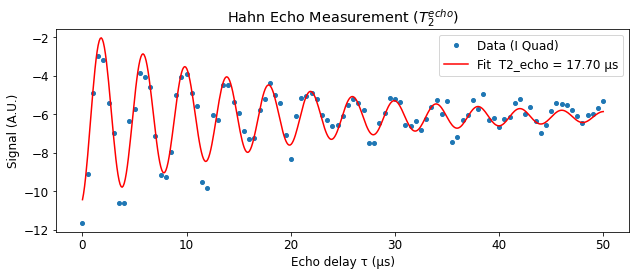

In [43]:
# --- 4. Fit & Plot ---
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

def echo_model(t, A, T2_echo, f, phi, C):
    return A * np.exp(-t / T2_echo) * np.cos(2 * np.pi * f * t + phi) + C

signal = i_data
A0   = (signal.max() - signal.min()) / 2
C0   = signal.mean()
T2_0 = delay_times[-1] / 3
# Fringe frequency should be close to f_detuning since Δf_real is refocused
f0   = config["f_detuning"]

try:
    popt, pcov = curve_fit(
        echo_model, delay_times, signal,
        p0=[A0, T2_0, f0, 0, C0],
        bounds=([0, 0, 0, -np.pi, -np.inf],
                [np.inf, np.inf, np.inf, np.pi, np.inf]),
        maxfev=10000
    )
    A, T2_echo, f_fit, phi, C = popt
    perr = np.sqrt(np.diag(pcov))
    print(f"T2_echo = {T2_echo:.3f} ± {perr[1]:.3f} µs")
    print(f"Fringe f = {f_fit*1e3:.1f} kHz  (expect ~{f0*1e3:.0f} kHz)")

    t_fine = np.linspace(delay_times[0], delay_times[-1], 500)
    plt.figure(figsize=(9, 4))
    plt.plot(delay_times, signal, "o", ms=4, label="Data (I Quad)")
    plt.plot(t_fine, echo_model(t_fine, *popt), "-r",
             label=f"Fit  T2_echo = {T2_echo:.2f} µs")
    plt.xlabel("Echo delay τ (µs)")
    plt.ylabel("Signal (A.U.)")
    plt.title("Hahn Echo Measurement ($T_2^{echo}$)")
    plt.legend()
    plt.tight_layout()
    plt.show()

except RuntimeError:
    print("Fit did not converge — adjust t_stop or initial guesses.")